# 5. Decision Tree / Karar Ağacı

**English theory:** [Classification](../Classification.md) · **Türkçe teori:** [Sınıflandırma](../Classification.tr.md) · [Notebook index / dizin](../README.md)

Learn splits by impurity reduction, choose tree complexity using CV, and verify the root split's information gain numerically.

**Türkçe:** Entropi ve bilgi kazancını hesaplayıp karar ağacının kök bölmesine bağlayacağız.

Run **Restart Kernel → Run All** to reproduce every output. Each notebook starts from raw local data and has no dependency on another notebook's variables. Saved tables and figures are actual executed outputs.

**Türkçe:** Sonuçları yeniden üretmek için çekirdeği yeniden başlatıp bütün hücreleri sırayla çalıştırın. Veri dosyaları repoda bulunur; başka bir notebook'un önceden çalıştırılması gerekmez.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, JSON

# Works when launched from this folder, Classification/, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
CLASSIFICATION_DIR = next(
    folder for base in candidates for folder in (base, base / "Classification")
    if (folder / "Classification.md").is_file()
    and (folder / "datasets" / "data.csv").is_file()
)
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="Environment"))

Python          3.10.11
NumPy            1.26.4
pandas            2.3.3
SciPy            1.13.1
scikit-learn      1.7.2
Matplotlib       3.10.9
Name: Environment, dtype: object

## Data and evaluation protocol / Veri ve ölçüm düzeni

The target is `B → 0`, `M → 1`. All six tabular classifiers use the **same stratified 80/20 split** (`random_state=42`), so their training CV scores can be compared. The final 114 rows are held out. Hyperparameters are chosen with five-fold CV **inside the 455 training rows**. A scaler belongs in a pipeline so each fold learns its own training minimum and maximum. Trees and GaussianNB do not need scaling.

**Türkçe:** Önce eğitim/test ayrımı yapılır. Ölçekleme ve model seçimi yalnız eğitim verisinden öğrenilir. Test verisi K, C veya derinlik seçmek için kullanılmaz. Eski notlardaki farklı ayrımla üretilmiş örnek yüzdeler bu çalıştırmayla birebir aynı olmak zorunda değildir.

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold

frame = pd.read_csv(CLASSIFICATION_DIR / "datasets" / "data.csv")
X = frame.drop(columns=["id", "diagnosis", "Unnamed: 32"])
y = frame["diagnosis"].map({"B": 0, "M": 1})
assert X.shape == (569, 30) and y.notna().all() and X.notna().all().all()
assert not X.columns.isin(["id", "diagnosis"]).any()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
display(pd.DataFrame({"all": y.value_counts(), "train": y_train.value_counts(),
                      "test": y_test.value_counts()}).rename(index={0: "Benign (0)", 1: "Malignant (1)"}))
display(X_train.head(3))
print(f"Train: {X_train.shape}; held-out test: {X_test.shape}")

,all,train,test
diagnosis,,,
Benign (0),357,285,72
Malignant (1),212,170,42


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,...,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,16.02,23.24,102.70,797.8,0.08206,0.06669,...,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452
170,12.32,12.39,78.85,464.1,0.10280,0.06981,...,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771
407,12.85,21.37,82.63,514.5,0.07551,0.08316,...,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151


Train: (455, 30); held-out test: (114, 30)


## Entropy and information gain / Entropi ve bilgi kazancı

$$H(S)=-\sum_c p_c\log_2p_c,\qquad
IG=H(S)-\frac{|S_L|}{|S|}H(S_L)-\frac{|S_R|}{|S|}H(S_R).$$

A split should make the children purer than the parent. A deep tree can memorize training rows; `max_depth` and `min_samples_leaf` limit complexity. The full classifier uses 30 features; the readable tree below uses two and depth 2, fitted only on training rows.

**Türkçe:** Ağırlıklar çocuk düğümdeki örnek sayılarından gelir. Yalnız entropileri toplamak, küçük ve büyük çocukları eşit sayarak yanlış kazanç üretir.

In [3]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(DecisionTreeClassifier(criterion="entropy", random_state=SEED),
                      {"max_depth": [2, 3, 4, 5, None], "min_samples_leaf": [1, 3, 5]},
                      cv=cv, scoring="accuracy", n_jobs=1, error_score="raise")
search.fit(X_train, y_train)
model = search.best_estimator_
display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
        .sort_values("mean_test_score", ascending=False).head(10))
print("Selected using training CV:", search.best_params_)
print("Fitted depth:", model.get_depth(), "leaves:", model.get_n_leaves())

,params,mean_test_score,std_test_score
6,"{'max_depth': 4, 'min_samples_leaf': 1}",0.938462,0.016447
7,"{'max_depth': 4, 'min_samples_leaf': 3}",0.936264,0.020143
13,"{'max_depth': None, 'min_samples_leaf': 3}",0.931868,0.020143
10,"{'max_depth': 5, 'min_samples_leaf': 3}",0.929670,0.022628
8,"{'max_depth': 4, 'min_samples_leaf': 5}",0.927473,0.020382
11,"{'max_depth': 5, 'min_samples_leaf': 5}",0.927473,0.025631
3,"{'max_depth': 3, 'min_samples_leaf': 1}",0.925275,0.021308
4,"{'max_depth': 3, 'min_samples_leaf': 3}",0.925275,0.021308
14,"{'max_depth': None, 'min_samples_leaf': 5}",0.925275,0.022413
5,"{'max_depth': 3, 'min_samples_leaf': 5}",0.923077,0.015541


Selected using training CV: {'max_depth': 4, 'min_samples_leaf': 1}
Fitted depth: 4 leaves: 12


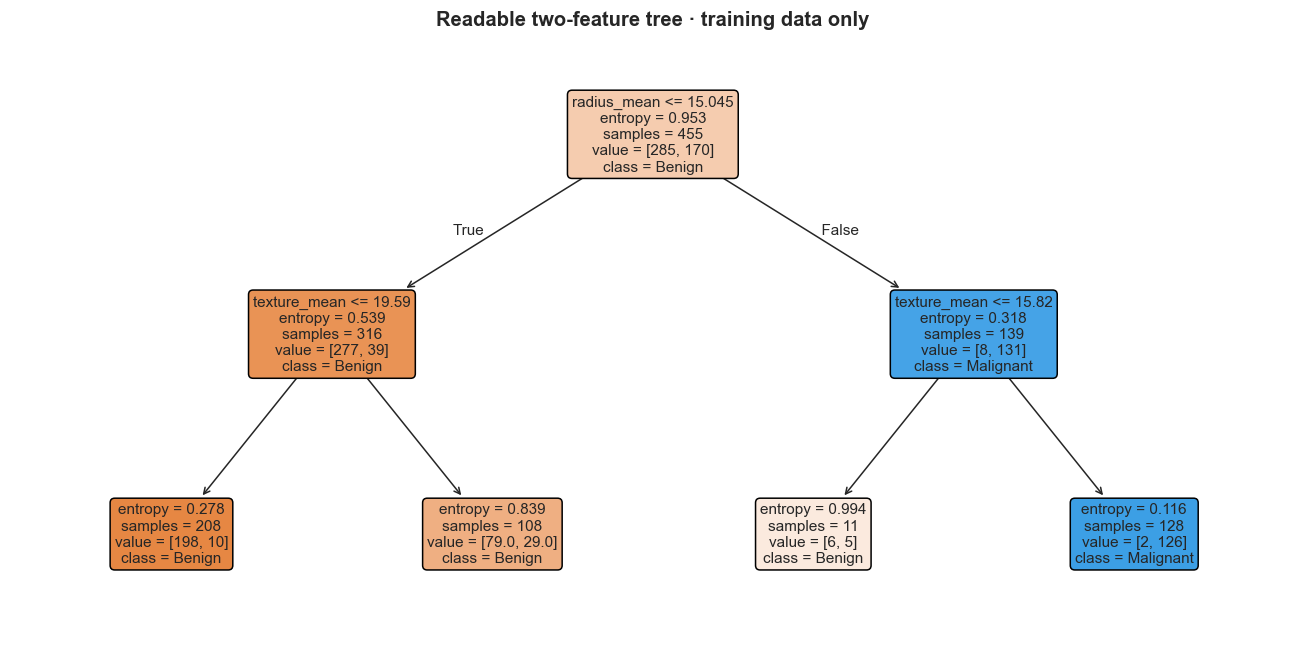

root_entropy              0.953416
weighted_child_entropy    0.471455
information_gain          0.481961
sklearn_gain              0.481961
dtype: float64

In [4]:
features_2d = ["radius_mean", "texture_mean"]
small_tree = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
small_tree.fit(X_train[features_2d], y_train)
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(small_tree, feature_names=features_2d, class_names=["Benign", "Malignant"],
          filled=True, rounded=True, proportion=False, precision=3, fontsize=10, ax=ax)
ax.set_title("Readable two-feature tree · training data only")
plt.tight_layout()
plt.show()

def entropy(labels):
    probability = np.bincount(np.asarray(labels), minlength=2) / len(labels)
    nonzero = probability[probability > 0]
    return -np.sum(nonzero * np.log2(nonzero))

feature_index = small_tree.tree_.feature[0]
threshold = small_tree.tree_.threshold[0]
# sklearn compares float32 input values with its stored threshold.
left = X_train[features_2d].to_numpy(dtype=np.float32)[:, feature_index] <= threshold
root_entropy = entropy(y_train)
weighted_child_entropy = (left.mean() * entropy(y_train.iloc[np.flatnonzero(left)])
                          + (~left).mean() * entropy(y_train.iloc[np.flatnonzero(~left)]))
information_gain = root_entropy - weighted_child_entropy
tree = small_tree.tree_
children = [tree.children_left[0], tree.children_right[0]]
library_gain = tree.impurity[0] - sum(tree.n_node_samples[node] / tree.n_node_samples[0]
                                     * tree.impurity[node] for node in children)
assert np.isclose(information_gain, library_gain)
display(pd.Series({"root_entropy": root_entropy, "weighted_child_entropy": weighted_child_entropy,
                   "information_gain": information_gain, "sklearn_gain": library_gain}))

              precision    recall  f1-score   support

      Benign     0.9000    1.0000    0.9474        72
   Malignant     1.0000    0.8095    0.8947        42

    accuracy                         0.9298       114
   macro avg     0.9500    0.9048    0.9211       114
weighted avg     0.9368    0.9298    0.9280       114



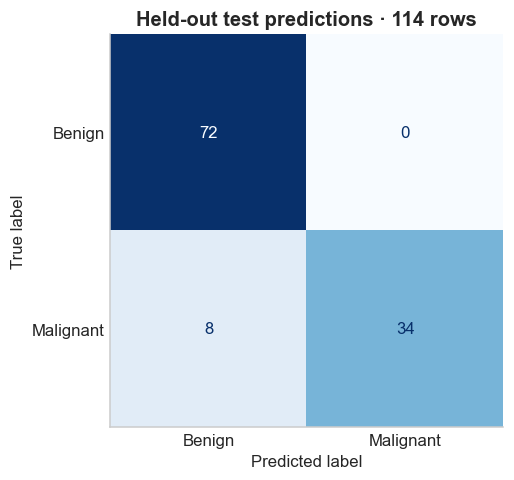

In [5]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

prediction = model.predict(X_test)
test_accuracy = accuracy_score(y_test, prediction)
test_macro_f1 = f1_score(y_test, prediction, average="macro")
print(classification_report(y_test, prediction, target_names=["Benign", "Malignant"], digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=["Benign", "Malignant"],
                                       cmap="Blues", colorbar=False)
plt.grid(False)
plt.title("Held-out test predictions · 114 rows")
plt.tight_layout()
plt.show()

## Measured result / Ölçülen sonuç

This summary is produced by the cells above; the runner also collects it in `Classification/notebook_results.json`. A single split is an educational experiment, not a guarantee for a different dataset.

**Türkçe:** Aşağıdaki değerler bu notebook'un gerçek çıktısıdır. Farklı veri veya ayrımlarda aynı sonuç garanti edilmez.

In [6]:
results = {"chapter": 5, "train_rows": len(X_train), "test_rows": len(X_test),
           "best_parameters": search.best_params_, "train_cv_accuracy": float(search.best_score_),
           "fitted_depth": model.get_depth(), "leaves": model.get_n_leaves(),
           "illustration_root_information_gain": float(information_gain),
           "test_accuracy": float(test_accuracy), "test_macro_f1": float(test_macro_f1)}
results["versions"] = versions
display(JSON(results, expanded=True))

<IPython.core.display.JSON object>